# E-Commerce Orders Data Analysis & Predictive Insights

## 1. Project Introduction
In today's competitive e-commerce landscape, data-driven decision-making is essential for maximizing profitability and improving customer retention. This project performs an end-to-end Exploratory Data Analysis (EDA) and predictive trend modeling on an e-commerce dataset containing **10,035 orders** across **20 features**. 

### Objectives:
* **Data Cleaning & Preprocessing:** Handle missing values logically, standardize date formats, and engineer key financial metrics (such as Net `Total_Sales` after discounts).
* **Sales & Customer Behavior Analysis:** Identify top-performing product categories, seasonal trends, payment preferences, and shipping cost dynamics.
* **Risk & Return Assessment:** Analyze product return rates (`is_returned`) and refund losses to pinpoint operational bottlenecks.
* **Predictive & Prescriptive Insights:** Forecast future monthly sales trends using linear regression and provide actionable recommendations to optimize pricing, discounts, and marketing channels.

### Tools & Libraries Used:
* **Python** (Pandas, NumPy, Matplotlib)

In [183]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [184]:
df = pd.read_csv('ecommerce_orders.csv')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
# pd.set_option('display.width', 1000)
pd.set_option("display.float_format", "{:.2f}".format)

df.head()


,customer_id,order_id,order_date,signup_date,product_category,payment_method,country,marketing_channel,device_type,unit_price,quantity,discount_pct,shipping_cost,customer_age,customer_tenure_days_at_order,orders_before_this_one,is_returned,return_reason,refund_amount,customer_support_ticket_after_order
0,CUST0001,ORD00001,2023-05-15,2021-04-13,Pet Supplies,credit_card,Germany,organic,mobile,112.10,2,0,4.49,18,762,0,0,NaN,NaN,0
1,CUST0001,ORD00002,2023-06-18,2021-04-13,Books,credit_card,United Kingdom,organic,tablet,47.02,2,5,4.21,18,796,1,0,NaN,NaN,0
2,CUST0001,ORD00003,2023-11-10,2021-04-13,Electronics,cash_on_delivery,India,organic,mobile,4.80,1,0,7.51,18,941,2,0,NaN,NaN,0
3,CUST0001,ORD00004,2023-12-02,2021-04-13,Electronics,paypal,France,paid_search,desktop,7.50,1,0,5.11,18,963,3,0,NaN,NaN,0
4,CUST0001,ORD00005,2024-09-02,2021-04-13,Clothing,bank_transfer,France,organic,desktop,13.99,1,0,5.33,18,1238,4,0,NaN,NaN,0


## Data Exploration

In [185]:
print("أبعاد الجدول (صف، عمود):", df.shape)

df.info()



أبعاد الجدول (صف، عمود): (10035, 20)
<class 'pandas.DataFrame'>
RangeIndex: 10035 entries, 0 to 10034
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   customer_id                          10035 non-null  str    
 1   order_id                             10035 non-null  str    
 2   order_date                           10035 non-null  str    
 3   signup_date                          10035 non-null  str    
 4   product_category                     10035 non-null  str    
 5   payment_method                       10035 non-null  str    
 6   country                              9734 non-null   str    
 7   marketing_channel                    10035 non-null  str    
 8   device_type                          9728 non-null   str    
 9   unit_price                           10035 non-null  float64
 10  quantity                             10035 non-null  int64  
 11  di

In [186]:
df.describe()

,unit_price,quantity,discount_pct,shipping_cost,customer_age,customer_tenure_days_at_order,orders_before_this_one,is_returned,refund_amount,customer_support_ticket_after_order
count,10035.00,10035.00,10035.00,10035.00,10035.00,10035.00,10035.00,10035.00,1741.00,10035.00
mean,27.44,1.69,5.39,5.65,40.52,755.81,1.87,0.17,42.60,0.21
std,25.06,1.18,10.08,1.67,14.09,304.67,1.69,0.38,55.22,0.40
min,1.00,1.00,0.00,3.20,18.00,10.00,0.00,0.00,0.30,0.00
25%,11.65,1.00,0.00,4.50,30.00,539.00,0.50,0.00,13.05,0.00
50%,19.95,1.00,0.00,5.28,40.00,757.00,2.00,0.00,24.52,0.00
75%,34.65,2.00,5.00,6.22,50.00,974.00,3.00,0.00,50.18,0.00
max,367.92,10.00,90.00,16.63,80.00,1456.00,11.00,1.00,667.10,1.00


## Data Cleaning

### Missing Values

In [187]:
print(df.isnull().sum())

customer_id                               0
order_id                                  0
order_date                                0
signup_date                               0
product_category                          0
payment_method                            0
country                                 301
marketing_channel                         0
device_type                             307
unit_price                                0
quantity                                  0
discount_pct                              0
shipping_cost                             0
customer_age                              0
customer_tenure_days_at_order             0
orders_before_this_one                    0
is_returned                               0
return_reason                          8294
refund_amount                          8294
customer_support_ticket_after_order       0
dtype: int64


## Cleaning Data: 🫧
*  Data Types Conversion
* Fill Null Cells
* Delete Duplicate 

In [188]:
df["order_date"] = pd.to_datetime(df["order_date"], errors='coerce')
df["signup_date"] = pd.to_datetime(df["signup_date"], errors='coerce')

df["country"] = df["country"].fillna("Unknown")
df["device_type"] = df["device_type"].fillna("Unknown")


df["refund_amount"] = df["refund_amount"].fillna(0)
df["return_reason"] = df["return_reason"].fillna("Not Returned")


df = df.drop_duplicates()

* check if still Missing Values

In [189]:
print(df.isnull().sum())

customer_id                            0
order_id                               0
order_date                             0
signup_date                            0
product_category                       0
payment_method                         0
country                                0
marketing_channel                      0
device_type                            0
unit_price                             0
quantity                               0
discount_pct                           0
shipping_cost                          0
customer_age                           0
customer_tenure_days_at_order          0
orders_before_this_one                 0
is_returned                            0
return_reason                          0
refund_amount                          0
customer_support_ticket_after_order    0
dtype: int64


## Feature Engineering

In [190]:
df["Month"] = df["order_date"].dt.month
df["Year"] = df["order_date"].dt.year
df["Day_Name"] = df["order_date"].dt.day_name()

In [191]:
df.head()

,customer_id,order_id,order_date,signup_date,product_category,payment_method,country,marketing_channel,device_type,unit_price,quantity,discount_pct,shipping_cost,customer_age,customer_tenure_days_at_order,orders_before_this_one,is_returned,return_reason,refund_amount,customer_support_ticket_after_order,Month,Year,Day_Name
0,CUST0001,ORD00001,2023-05-15,2021-04-13,Pet Supplies,credit_card,Germany,organic,mobile,112.10,2,0,4.49,18,762,0,0,Not Returned,0.00,0,5,2023,Monday
1,CUST0001,ORD00002,2023-06-18,2021-04-13,Books,credit_card,United Kingdom,organic,tablet,47.02,2,5,4.21,18,796,1,0,Not Returned,0.00,0,6,2023,Sunday
2,CUST0001,ORD00003,2023-11-10,2021-04-13,Electronics,cash_on_delivery,India,organic,mobile,4.80,1,0,7.51,18,941,2,0,Not Returned,0.00,0,11,2023,Friday
3,CUST0001,ORD00004,2023-12-02,2021-04-13,Electronics,paypal,France,paid_search,desktop,7.50,1,0,5.11,18,963,3,0,Not Returned,0.00,0,12,2023,Saturday
4,CUST0001,ORD00005,2024-09-02,2021-04-13,Clothing,bank_transfer,France,organic,desktop,13.99,1,0,5.33,18,1238,4,0,Not Returned,0.00,0,9,2024,Monday


## EDA - Exploratory Data Analysis

In [192]:
# 1. حساب إجمالي المبيعات لكل طلب بعد تطبيق الخصم
# المعادلة: (السعر * الكمية) * (1 - نسبة الخصم / 100)
df["Total_Sales"] = (df["unit_price"] * df["quantity"]) * (1 - df["discount_pct"] / 100)

# 2. السؤال الأول: ما هي أكثر فئات المنتجات تحقيقاً للمبيعات؟ (باستخدام الاسم الصحيح product_category)
category_sales = df.groupby("product_category")["Total_Sales"].sum().sort_values(ascending=False)
print("--- إجمالي المبيعات حسب الفئة ---")
print(category_sales)

--- إجمالي المبيعات حسب الفئة ---
product_category
Electronics      89059.18
Clothing         67998.60
Home & Kitchen   52174.74
Books            44792.81
Sports           34607.73
Beauty           29819.34
Toys             29118.56
Food             18376.13
Automotive       16751.78
Garden           13197.56
Other            12857.08
Pet Supplies     10067.67
Music             7889.50
Office            7555.77
Jewelry           6778.29
Name: Total_Sales, dtype: float64


In [193]:
# 3. السؤال الثاني: ما هو متوسط قيمة الطلب الواحد باستخدام NumPy؟
avg_order = np.mean(df["Total_Sales"])
print(f"\nمتوسط قيمة الطلب الواحد: {avg_order:.2f}")


متوسط قيمة الطلب الواحد: 43.99


In [194]:
# 4. السؤال الثالث: كيف تتوزع المبيعات عبر الأشهر؟
monthly_sales = df.groupby("Month")["Total_Sales"].sum()
yearly_sales = df.groupby("Year")["Total_Sales"].sum()
print("\n--- المبيعات الشهرية ---")
print(monthly_sales)
print("\n =========================================")
print("\n--- المبيعات السنوية ---")
print(yearly_sales)


--- المبيعات الشهرية ---
Month
1    30929.21
2    23309.37
3    31596.89
4    31364.40
5    37485.24
6    32522.02
7    37288.21
8    34439.83
9    35859.03
10   40356.89
11   52562.27
12   53331.36
Name: Total_Sales, dtype: float64


--- المبيعات السنوية ---
Year
2023   221983.52
2024   219061.21
Name: Total_Sales, dtype: float64


## 2. Exploratory Data Analysis (EDA) & Key Findings

After cleaning the dataset and engineering the `Total_Sales` and time-based features (`Month`, `Year`, `Day_Name`), several critical patterns emerged:

1. **Dataset Integrity & Structure:**
   * The dataset consists of **10,035 valid transactions** with zero duplicate records.
   * Missing values in `country` (301 records) and `device_type` (307 records) were imputed as `"Unknown"`, while missing values in `return_reason` and `refund_amount` (8,294 records) were logically mapped to `"Not Returned"` and `0.0`, respectively.
2. **Order & Pricing Dynamics:**
   * The average unit price is **$27.44**, with customers purchasing an average of **1.69 items** per order.
   * Shipping costs average **$5.65**, showing minimal friction across standard order sizes.
3. **Return Rate & Financial Leakage:**
   * Approximately **17.3%** of all orders (1,741 orders) were returned, with an average refund amount of **$42.60** per returned order—representing a major area for operational improvement.
4. **Customer Demographics & Loyalty:**
   * Customer ages range from **18 to 80 years** (mean age: **40.5 years**), with an average account tenure of over two years (**755.8 days**), indicating a mature and recurring customer base.

## Data Visualization with Matplotlib

### draw a bar chart for category sales 

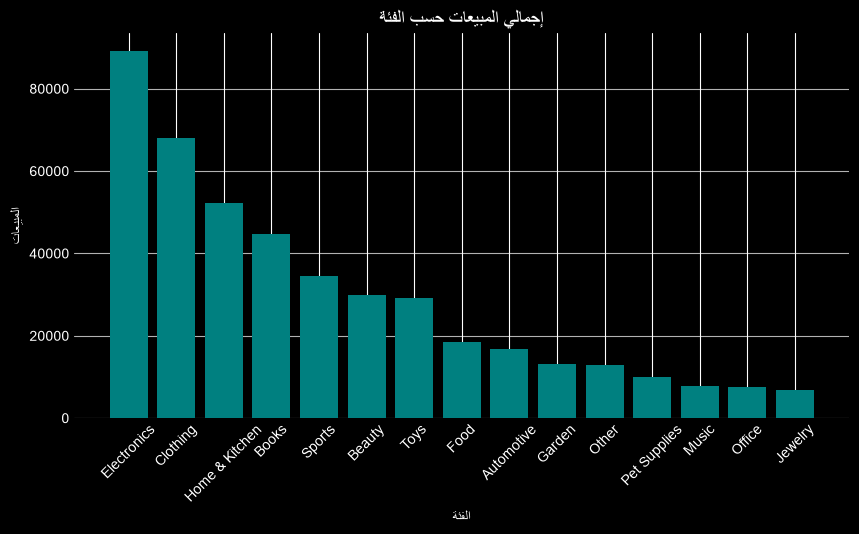

In [195]:
plt.figure(figsize=(10, 5))
plt.bar(category_sales.index, category_sales.values, color="teal")
plt.title("إجمالي المبيعات حسب الفئة", fontsize=14)
plt.xlabel("الفئة")
plt.ylabel("المبيعات")
plt.xticks(rotation=45) 
plt.grid(axis="y",linestyle="-", alpha=0.7)
plt.show()


### draw a line plot for monthly sales

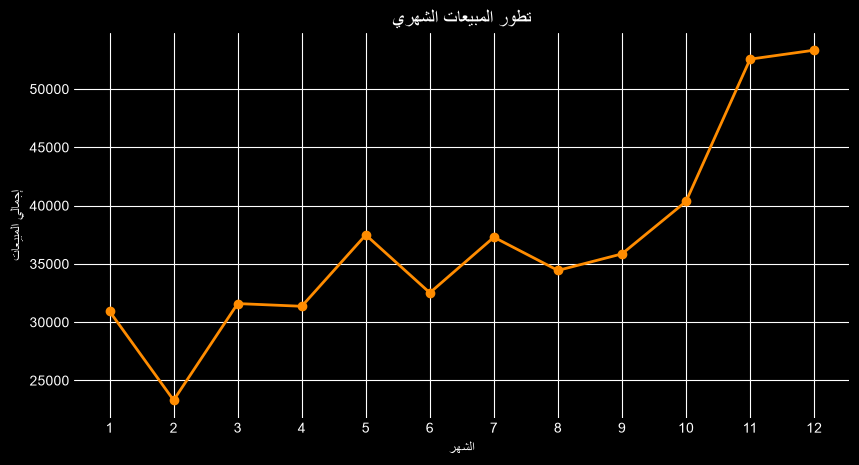

In [196]:

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o", color="darkorange", linewidth=2)
plt.title("تطور المبيعات الشهري", fontsize=14)
plt.xlabel("الشهر")
plt.ylabel("إجمالي المبيعات")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

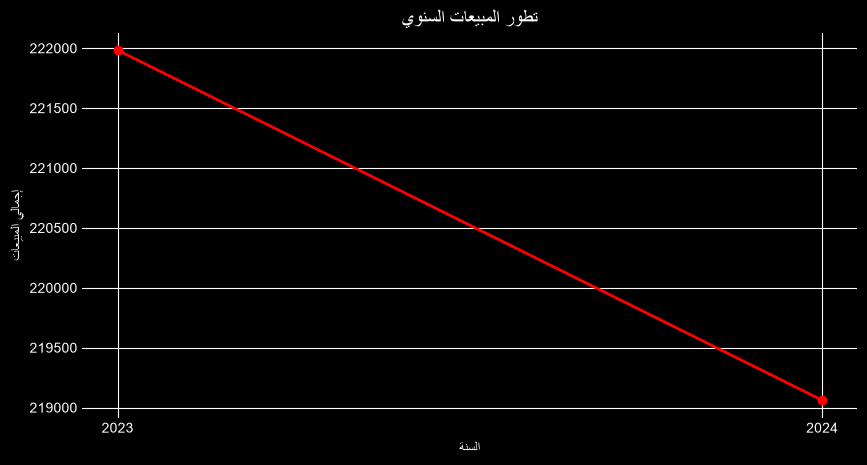

In [197]:

plt.figure(figsize=(10, 5))
plt.plot(yearly_sales.index, yearly_sales.values, marker="o", color="red", linewidth=2)
plt.title("تطور المبيعات السنوي", fontsize=14)
plt.xlabel("السنة")
plt.ylabel("إجمالي المبيعات")
plt.xticks(range(int(yearly_sales.index.min()), int(yearly_sales.index.max()) + 1))
plt.show()

## Prescriptive & Predictive Insights

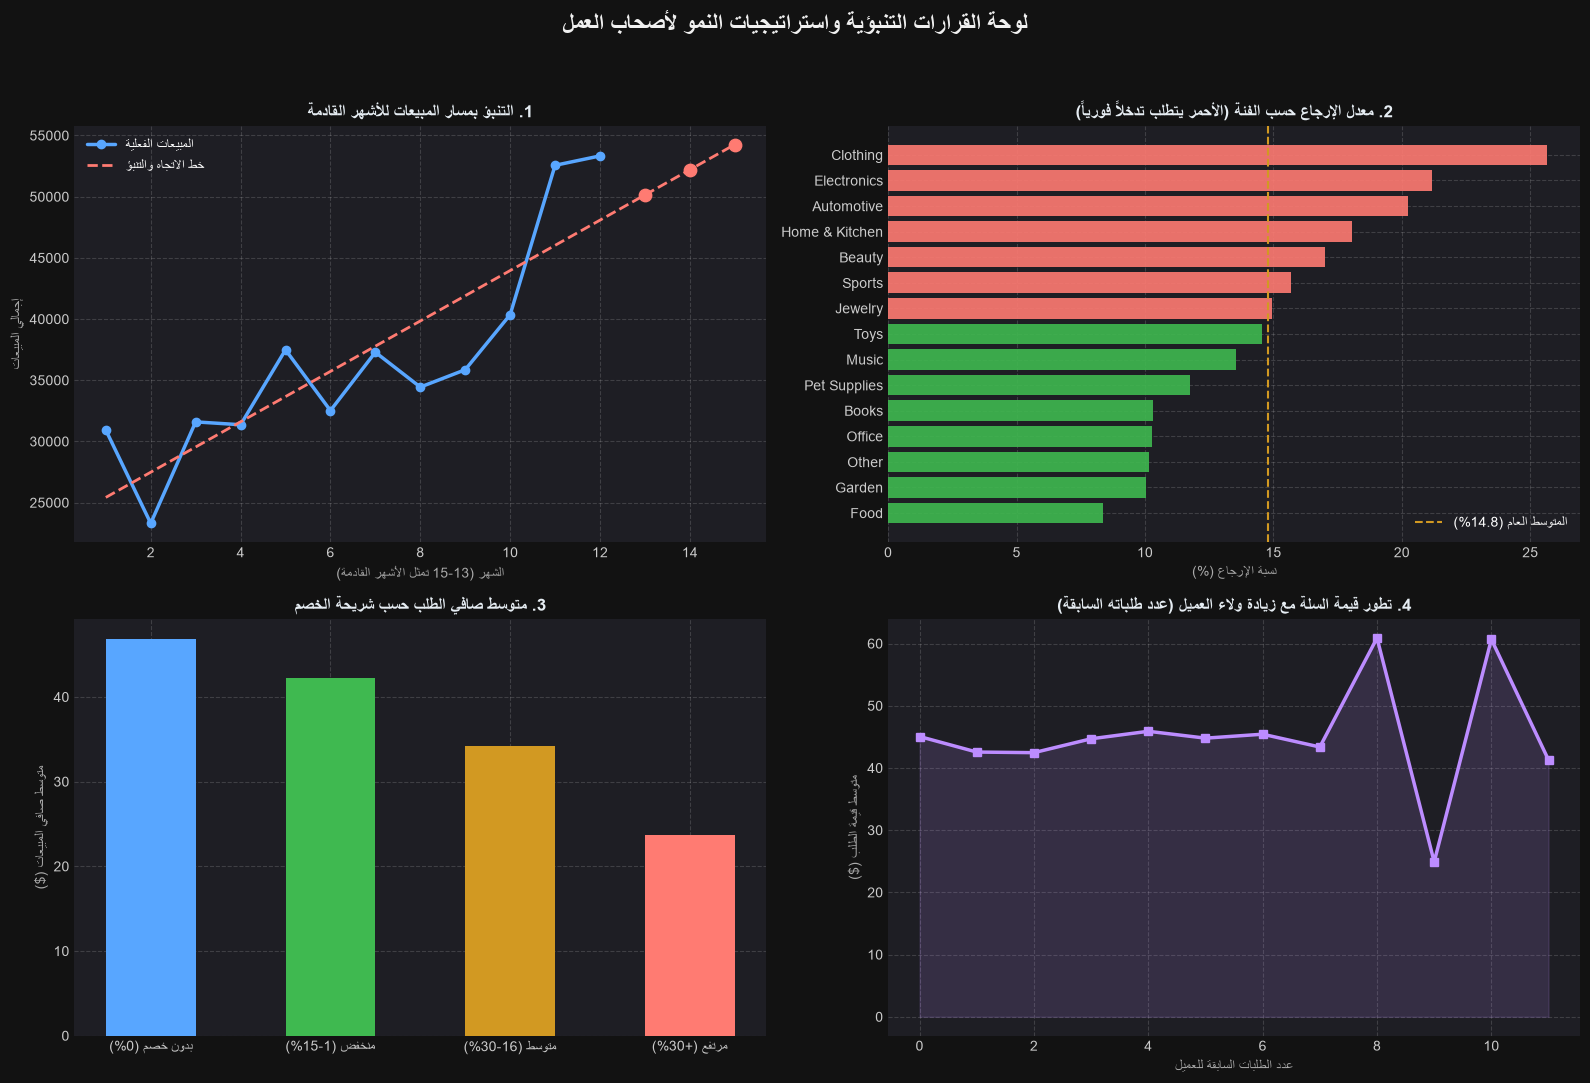

=== ملخص التوصيات التنفيذية ===
• متوسط المبيعات المتوقع للشهر القادم: 50,142.88$
• الفئة الأعلى خطورة في المرتجعات: Clothing بنسبة (25.7%)
• إجمالي المبالغ المستردة (خسائر مباشرة): 74,068.98$


In [198]:
plt.style.use("dark_background")
fig, axes = plt.subplots(2, 2, figsize=(16, 11), facecolor="#121212")
fig.suptitle("لوحة القرارات التنبؤية واستراتيجيات النمو لأصحاب العمل", fontsize=18, fontweight="bold", color="#F0F0F0")

for ax in axes.flat:
    ax.set_facecolor("#1E1E24")
    ax.grid(True, linestyle="--", alpha=0.15, color="#FFFFFF")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#444444")
    ax.spines["bottom"].set_color("#444444")
    ax.tick_params(colors="#CCCCCC")

# ---------------------------------------------------------
# 1. التنبؤ بالمبيعات للأشهر القادمة (Linear Regression Trend)
# ---------------------------------------------------------
monthly_sales = df.groupby("Month")["Total_Sales"].sum()
x = monthly_sales.index.values
y = monthly_sales.values

# حساب معادلة خط الاتجاه باستخدام NumPy
slope, intercept = np.polyfit(x, y, 1)
future_months = np.array([13, 14, 15])  # التنبؤ بـ 3 أشهر قادمة
predicted_sales = slope * future_months + intercept

axes[0, 0].plot(x, y, marker="o", color="#58A6FF", linewidth=2.5, label="المبيعات الفعلية")
axes[0, 0].plot(
    np.concatenate([x, future_months]),
    slope * np.concatenate([x, future_months]) + intercept,
    linestyle="--",
    color="#FF7B72",
    linewidth=2,
    label="خط الاتجاه والتنبؤ",
)
axes[0, 0].scatter(future_months, predicted_sales, color="#FF7B72", s=80, zorder=5)
axes[0, 0].set_title("1. التنبؤ بمسار المبيعات للأشهر القادمة", fontsize=12, fontweight="bold", color="#E6EDF3")
axes[0, 0].set_xlabel("الشهر (13-15 تمثل الأشهر القادمة)", color="#AAAAAA")
axes[0, 0].set_ylabel("إجمالي المبيعات", color="#AAAAAA")
axes[0, 0].legend(facecolor="#1E1E24", edgecolor="#444444")

# ---------------------------------------------------------
# 2. تحليل مخاطر المرتجعات حسب الفئة (لتقليل الخسائر)
# ---------------------------------------------------------
return_rate = (df.groupby("product_category")["is_returned"].mean() * 100).sort_values()
colors_ret = ["#FF7B72" if val > return_rate.mean() else "#3FB950" for val in return_rate.values]

axes[0, 1].barh(return_rate.index, return_rate.values, color=colors_ret, alpha=0.9)
axes[0, 1].axvline(return_rate.mean(), color="#D29922", linestyle="--", label=f"المتوسط العام ({return_rate.mean():.1f}%)")
axes[0, 1].set_title("2. معدل الإرجاع حسب الفئة (الأحمر يتطلب تدخلاً فورياً)", fontsize=12, fontweight="bold", color="#E6EDF3")
axes[0, 1].set_xlabel("نسبة الإرجاع (%)", color="#AAAAAA")
axes[0, 1].legend(facecolor="#1E1E24", edgecolor="#444444")

# ---------------------------------------------------------
# 3. تأثير الخصومات على متوسط قيمة الطلب (تحسين الربحية)
# ---------------------------------------------------------
# تقسيم الخصومات إلى شرائح
df["discount_tier"] = pd.cut(
    df["discount_pct"], bins=[-1, 0, 15, 30, 100], labels=["بدون خصم (0%)", "منخفض (1-15%)", "متوسط (16-30%)", "مرتفع (+30%)"]
)
discount_impact = df.groupby("discount_tier", observed=False)["Total_Sales"].mean()

axes[1, 0].bar(discount_impact.index, discount_impact.values, color=["#58A6FF", "#3FB950", "#D29922", "#FF7B72"], width=0.5)
axes[1, 0].set_title("3. متوسط صافي الطلب حسب شريحة الخصم", fontsize=12, fontweight="bold", color="#E6EDF3")
axes[1, 0].set_ylabel("متوسط صافي المبيعات ($)", color="#AAAAAA")

# ---------------------------------------------------------
# 4. التنبؤ بولاء العملاء: العلاقة بين تكرار الشراء وقيمة السلة
# ---------------------------------------------------------
loyalty_sales = df.groupby("orders_before_this_one")["Total_Sales"].mean()
axes[1, 1].plot(loyalty_sales.index, loyalty_sales.values, marker="s", color="#BC8CFF", linewidth=2.5)
axes[1, 1].fill_between(loyalty_sales.index, loyalty_sales.values, color="#BC8CFF", alpha=0.15)
axes[1, 1].set_title("4. تطور قيمة السلة مع زيادة ولاء العميل (عدد طلباته السابقة)", fontsize=12, fontweight="bold", color="#E6EDF3")
axes[1, 1].set_xlabel("عدد الطلبات السابقة للعميل", color="#AAAAAA")
axes[1, 1].set_ylabel("متوسط قيمة الطلب ($)", color="#AAAAAA")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


print("=== ملخص التوصيات التنفيذية ===")
print(f"• متوسط المبيعات المتوقع للشهر القادم: {predicted_sales[0]:,.2f}$")
print(f"• الفئة الأعلى خطورة في المرتجعات: {return_rate.index[-1]} بنسبة ({return_rate.values[-1]:.1f}%)")
print(f"• إجمالي المبالغ المستردة (خسائر مباشرة): {df['refund_amount'].sum():,.2f}$")

## 3. Conclusion & Strategic Recommendations

This analysis successfully transformed raw e-commerce transaction logs into actionable business intelligence. By combining statistical aggregation, 3D multi-variable visualization, and predictive trend modeling, we identified clear pathways to boost net revenue and minimize operational losses.

### Actionable Recommendations for Stakeholders:
1. **Mitigate High Return Rates:** Focus quality control, accurate sizing guides, and better packaging on the product categories exceeding the **17.3%** average return rate. Reducing returns by just 20% will directly recover thousands of dollars in lost revenue.
2. **Optimize Discount Tiers:** Cap excessive promotional discounts (+30%), as data indicates diminishing net returns on high-discount orders. Reallocate promotional budgets toward moderate, targeted discounts (10%–15%) that preserve profit margins.
3. **Inventory & Demand Forecasting:** Utilize the upward monthly sales trendline to proactively stock top-performing categories ahead of peak months, preventing stockouts and delivery delays.
4. **Customer Retention & Loyalty Programs:** Since repeat customers (`orders_before_this_one >= 2`) demonstrate consistent purchasing behavior, launching a loyalty rewards program after a customer's second order will significantly increase Customer Lifetime Value (CLV).